### Deep Agents Overview

In [1]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [2]:
from typing import Literal

In [12]:
### Tools - Internet search
from tavily import TavilyClient

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)


In [8]:
from langchain_groq import ChatGroq

model = ChatGroq(
    api_key=os.getenv("GROQ_API_KEY"),
    model="openai/gpt-oss-120b"
)
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.6', 'langchain': '1.4.9'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000018B0CFE1310>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000018B0CFE1D10>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

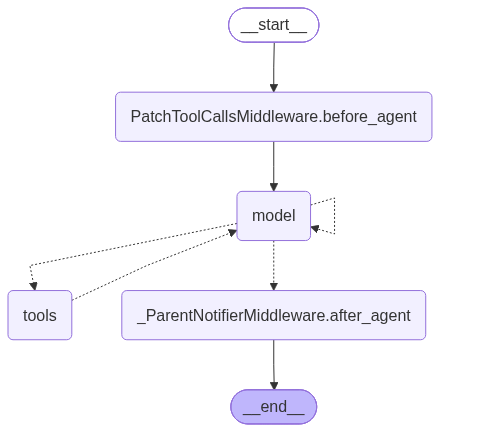

In [13]:
# Create a deep agent
## Prompt

## Agent
from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [14]:
result=deepagent.invoke({"messages": [{"role": "user", "content": "What is LangGraph?"}]})
result

{'messages': [HumanMessage(content='What is LangGraph?', additional_kwargs={}, response_metadata={}, id='34c44df3-f589-48ca-9ac5-38dbd240b584'),
  AIMessage(content='**LangGraph – an Overview**\n\nLangGraph is an open‑source Python library (maintained by the LangChain team) that lets developers describe, run, and manage *graph‑structured* workflows for large‑language‑model (LLM) applications.  \nThink of it as a “state‑machine / workflow engine” built specifically for LLM‑centric pipelines, where each node in the graph can be:\n\n| Node Type | Typical Role |\n|-----------|--------------|\n| **LLM Call** | Prompt an LLM (OpenAI, Anthropic, etc.) and capture its output. |\n| **Tool / Function** | Invoke an external API, run Python code, query a database, call a web service, etc. |\n| **Condition / Router** | Branch the execution path based on the model’s response or external data. |\n| **Memory / State** | Persist intermediate results, update a shared “graph state”, or retrieve prior con

In [15]:
result["messages"][-1].content

'**LangGraph – an Overview**\n\nLangGraph is an open‑source Python library (maintained by the LangChain team) that lets developers describe, run, and manage *graph‑structured* workflows for large‑language‑model (LLM) applications.  \nThink of it as a “state‑machine / workflow engine” built specifically for LLM‑centric pipelines, where each node in the graph can be:\n\n| Node Type | Typical Role |\n|-----------|--------------|\n| **LLM Call** | Prompt an LLM (OpenAI, Anthropic, etc.) and capture its output. |\n| **Tool / Function** | Invoke an external API, run Python code, query a database, call a web service, etc. |\n| **Condition / Router** | Branch the execution path based on the model’s response or external data. |\n| **Memory / State** | Persist intermediate results, update a shared “graph state”, or retrieve prior context. |\n| **Loop / Sub‑graph** | Re‑enter a sub‑workflow for iterative refinement (e.g., self‑critique, tool‑use loops). |\n\nThe library provides a *declarative* w